In [22]:
from src.gaussian_mixture import GaussianMixtureMAR

from src.propensity_score_estimator import PropensityScoreEstimator

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

#=== FOR NMMIPW ===#
#import rpy2.robjects as ro
#from rpy2.robjects import pandas2ri, numpy2ri
#from rpy2.robjects.conversion import localconverter
#from rpy2.robjects.packages import importr
#nmm = importr("NMMIPW")
#==================#

In [ ]:
import sys, numpy, torch
print(sys.executable)
print(numpy.__file__)
print(torch.from_numpy(numpy.zeros(3)))

In [23]:
eps_vals = [0.0, 0.1, 0.3, 0.5, 0.7, 0.9]

In [24]:
n = 2000
d = 3
kk = (1, 20)

$$ 
\mathbb P (M=\mathbf 0 \mid x)= 1 - \mathbb P (M=(1,0,0) \mid x) - \mathbb P (M=(0,1,0) \mid x)
$$

- estimate $\mathbb P (M=(1,0,0) \mid x)$

$$
\mathbb P (M = (1,0,0) \mid x) = \mathbb P (M = (1,0,0) \mid x_2, x_3) = \frac{p(x_2, x_3 \mid M=(1,0,0))\mathbb P(M=(1,0,0))}{p(x_2, x_3)}
$$

Uncomment below to check the details of the class for estimating propensity score

In [ ]:
# class PropensityScoreEstimator(MotivatingExample):

#     def __init__(self, type='mar', n=5000, d=3, alpha=0.7, model_k=(0, 10), p=0.1, B=100, n_jobs=15, device='cpu', dtype=torch.float32):
#         super().__init__(type, n, d, alpha, model_k, p, B, n_jobs, device, dtype)
#         self.X = self.get_X()
#         self.M = self.get_M(self.X)

#         self.model0 = GaussianMixtureMAR(k_range=(0,10))
#         self.model0.fit(self.X, self.M)

#     def get_Xtest_cond_x1(self):
#         mu = torch.zeros(self.d, device=self.device)
#         cov = torch.eye(self.d, device=self.device)
#         X = torch.distributions.MultivariateNormal(mu, cov).sample((self.n,))
#         X[:, 0] = torch.distributions.Normal(0,1).sample() * torch.ones(self.n, device=self.device)
#         X[:, 1]= self._conditional(X[:, 0])
#         return X

#     def _log_prob_xp_cond_m(self, Xtest, m):
#         Xp = self.X[(self.M==m).all(dim=1)][:, m.bool()]
#         Mp = torch.ones_like(Xp, device=Xp.device)
#         g = GaussianMixtureMAR(k_range=(0,10))
#         g.fit(Xp, Mp)
#         return g.log_prob_x(Xtest[:, m.bool()])

#     def _log_prob_xp(self, Xtest, m):
#         return self.model0.log_prob_x(Xtest, torch.where(m==1))

#     def _phat_M(self, m):
#         return ((self.M == m).all(dim=1)).sum() / self.n

#     def _estimate(self, Xtest, m):
#         lp1 = self._log_prob_xp_cond_m(Xtest, m)
#         lp2 = self._log_prob_xp(Xtest, m)
#         p1 = self._phat_M(m)
#         return (lp1 - lp2).exp() * p1

#     def estimate_by_subtraction(self, Xtest):
#         m = torch.ones(self.d, device=self.device)
#         m1 = m.clone()
#         m2 = m.clone()
#         m1[0] = 0
#         m2[1] = 0
#         raw_est = 1 - self._estimate(Xtest, m1) - self._estimate(Xtest, m2)
#         return torch.clamp(raw_est, min=0)

#     def estimate_direct(self, Xtest):
#         m = torch.ones(self.d, device=self.device)
#         return self._estimate(Xtest, m)

In [31]:
pse = PropensityScoreEstimator(d=d, n=n)

In [ ]:
# test not fixing any variable
# Xtest = pse.get_X()

In [ ]:
Xtest = pse.get_Xtest_cond_x1()
est_by_sub = pse.estimate_by_subtraction(Xtest)
est_direct = pse.estimate_direct(Xtest)

In [29]:
X1test = Xtest[:,0]
X2test = Xtest[:,1]

norm = torch.distributions.Normal(0., 1.)
truth = (norm.cdf(X1test) + norm.cdf(X2test)) / 3

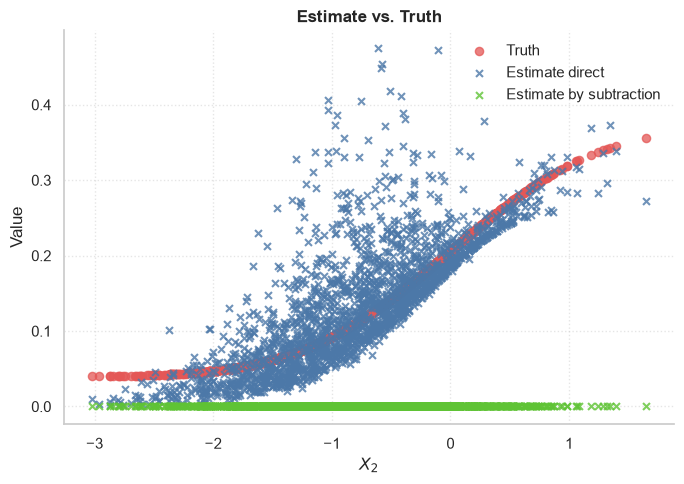

In [32]:
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    X2test, truth,
    s=35,
    color="#E45756",
    alpha=0.75,
    marker="o",
    label="Truth",
    zorder=2,
)

ax.scatter(
    X2test, est_direct,
    s=25,
    color="#4C78A8",
    alpha=0.8,
    marker="x",
    linewidths=1.5,
    label="Estimate direct",
    zorder=3,
)

ax.scatter(
    X2test, est_by_sub,
    s=25,
    color="#5FC335",
    alpha=0.8,
    marker="x",
    linewidths=1.5,
    label="Estimate by subtraction",
    zorder=3,
)

ax.set_xlabel(r"$X_2$")
ax.set_ylabel("Value")
ax.set_title("Estimate vs. Truth", fontweight="bold")
ax.legend(frameon=False)
ax.grid(True, linestyle=":", alpha=0.5)

sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
class IPW_Estimator:

    def __init__(self, k_range, criterion="bic", cov_type='uni_diag', n_init=5):
        self.gmm = GaussianMixtureMAR(k_range=k_range, criterion=criterion, cov_type=cov_type, n_init=n_init)
        self.gmm_m0 = GaussianMixtureMAR(k_range=k_range, criterion=criterion, cov_type=cov_type, n_init=n_init)
        self.gmm_m1 = GaussianMixtureMAR(k_range=k_range, criterion=criterion, cov_type=cov_type, n_init=n_init)
        self.gmm_m2 = GaussianMixtureMAR(k_range=k_range, criterion=criterion, cov_type=cov_type, n_init=n_init)
        self.pm0 = 0
        self.pm1 = 0
        self.pm2 = 0
        
    def fit(self, X, M):
        # Estimate p(x)
        self.gmm.fit(X, M)
    
        # Estimate p(x|M=0) + Estimate P(M=0)
        idx_m0 = M.sum(dim=1)==d
        self.gmm_m0.fit(X[idx_m0], M[idx_m0])
        self.pm0 = ((M.sum(dim=1) == d).sum() / M.shape[0]).item()

        # Estimate p(x|M=m_1)
        pattern = torch.tensor([0., 1., 1.], dtype=M.dtype, device=M.device)

        mask1 = (M == pattern).all(dim=1)   # (N,) boolean: True where the row of M is [1, 0, 0]
        print(X[mask1])
        self.gmm_m1.fit(X[mask1], M[mask1])
        self.pm1 = ((mask1).sum() / M.shape[0]).item()

        # Estimate p(x|M=m_2)
        pattern = torch.tensor([1., 0., 1.], dtype=M.dtype, device=M.device)
        mask2 = (M == pattern).all(dim=1)   # (N,) boolean: True where the row of M is [1, 0, 0]

        print(mask2)
        print(X[mask2])
        self.gmm_m2.fit(X[mask2], M[mask2])
        self.pm2 = ((mask2).sum() / M.shape[0]).item()


        
    
    def evaluate(self, X):
        # Estimate P(M=0|x) = p(x|M=0) * P(M=0) / p(x)
        #return torch.minimum((torch.exp(self.gmm_m0.log_prob_x(X)  - self.gmm.log_prob_x(X) ) * self.pm0)[:,0], torch.tensor(1))
         return torch.minimum((torch.exp(self.gmm_m0.log_prob_x(X)) * self.pm0 / torch.exp(self.gmm.log_prob_x(X)))[:,0], torch.tensor(1))

#log_prob_x_m(self, X, M)
         return torch.minimum(1-
                              # Pattern [0., 1., 1.]
                             (torch.exp(self.gmm_m1.log_prob_x(X[:, 2:3])) * self.pm1 / torch.exp(self.gmm.log_prob_x_m(X, M)))[:,0]-
                              # Pattern [1., 0., 1.]
                             (torch.exp(self.gmm_m2.log_prob_x(X[:, 1,3])) * self.pm2 / torch.exp(self.gmm.log_prob_x_m(X, M)))[:,0], 
                             torch.tensor(1))



In [ ]:
def eval_p0_true(X):
    U1, U2 = dg.latent_uniforms(X)
    G1 = torch.maximum(U1, dg.c)
    G2 = torch.maximum(U2, dg.c)
    return (G1+G2)/3

In [ ]:
def est_ipw_quant(X_ipw, M_ipw, X_quant, M_quant):
    ipw_est = IPW_Estimator(k_range=kk)
    ipw_est.fit(X_ipw, M_ipw)
    
    p0_test = ipw_est.evaluate(Xtest)

    idx_m0 = M_quant.sum(dim=1)==d
    Xm0 = X_quant[idx_m0]
    Xm0_np = Xm0.detach().numpy()
    p0_train = ipw_est.evaluate(Xm0)
    quantile_p0 = np.quantile(Xm0_np[:,0], 0.1, method="inverted_cdf", weights=1/p0_train.detach().numpy())

    return p0_test, p0_train, quantile_p0

In [ ]:
X = dg.sample_truth(n, d)
M = dg.generate_MNAR1(X, 0.0)
# Ampute X accordingly
Xm = X.clone()
Xm[M == 0] = 0

print(M)
X

pattern = torch.tensor([1., 0., 1.], dtype=M.dtype, device=M.device)
mask = (M == pattern).all(dim=1)   # (N,) boolean: True where the row of M is [1, 0, 0]
X_sel = X[mask]                    # rows of X that correspond to those rows of M
X_sel

GaussianMixtureMAR(k_range=k_range, criterion=criterion, cov_type=cov_type, n_init=n_init)

In [ ]:
X = dg.sample_truth(n, d)
M = dg.generate_MNAR1(X, 0.0)

pattern = torch.tensor([0., 1., 1.], dtype=M.dtype, device=M.device)
mask = (M == pattern).all(dim=1)   # (N,) boolean: True where the row of M is [1, 0, 0]
X[mask]

In [ ]:
B = 1
n_test = int(n/2)
cross_fitting = False

quantile_unweighted = np.zeros(B)

p0_true_train = []
p0_true_test = np.zeros((B, n_test))
quantile_p0_true = np.zeros(B)

p0_nmmipw_train = []
p0_nmmipw_test = np.zeros((B, n_test))
quantile_p0_nmmipw = np.zeros(B)

p0_est_train = []
if cross_fitting:
    p0_est_test = np.zeros((B, 3, n_test))
    quantile_p0_est = np.zeros((B, 3))
else:
    p0_est_test = np.zeros((B, n_test))
    quantile_p0_est = np.zeros(B)


for i in range(B):
    # Sample X, M
    X = dg.sample_truth(n, d)
    M = dg.generate_MNAR1(X, 0.0)
    # Ampute X accordingly
    Xm = X.clone()
    Xm[M == 0] = 0

    # Determine unweighted quantile and that using the true IPW (on the whole dataset)
    idx_m0 = M.sum(dim=1)==d
    Xm0 = Xm[idx_m0]
    Xm0_np = Xm0.detach().numpy()
    quantile_unweighted[i] = np.quantile(Xm0_np[:,0], 0.1)
    quantile_p0_true[i] = np.quantile(Xm0_np[:,0], 0.1, method="inverted_cdf", weights=1/np.maximum(eval_p0_true(Xm0).detach().numpy(), 0.01))

    # evaluate P(M=0|x) on a test set for evaluation
    Xtest = dg.sample_truth(n_test, d)
    p0_true_test[i] = eval_p0_true(Xtest)
    p0_true_train.append(eval_p0_true(Xm0))
    
    #=== FOR NMMIPW ===#
    #with localconverter(ro.default_converter + pandas2ri.converter + numpy2ri.converter):
    #    r_X = ro.conversion.py2rpy(Xm.detach().numpy())
    #    r_O = ro.conversion.py2rpy(M.detach().numpy().astype(np.int32))
    
    #pre = nmm.nmm_preprocessing(r_X, r_O)
    #ps = nmm.PS(r_X, pre.rx2("R"), pre.rx2("pattern"))
    
    #with localconverter(ro.default_converter + pandas2ri.converter + numpy2ri.converter):
    #    r_Xtest = ro.conversion.py2rpy(Xtest.detach().numpy())
    #p0_nmmipw_test[i] = np.asarray(predict_prop(ps, r_Xtest, pre.rx2("pattern")))

    #p0_nmmipw_train.append(np.asarray(ps.rx2("prop")))
    #quantile_p0_nmmipw[i] = np.quantile(Xm0_np[:,0], 0.1, method="inverted_cdf", weights=1/p0_nmmipw_train[i])
    quantile_p0_nmmipw[i] = 0
    #==================#

    # cross-fit IPW and quantile estimation
    if cross_fitting:
        X1, X2, M1, M2 = train_test_split(Xm, M, test_size=0.5)
        
        for j, X_ipw, M_ipw, X_quant, M_quant in [(1, X1, M1, X2, M2), (2, X2, M2, X1, M1)]:
            p0_est_test[i][j], p0_train, quantile_p0_est[i][j] = est_ipw_quant(X_ipw, M_ipw, X_quant, M_quant)
            p0_est_train.append({f'fold{j}': p0_train})
            
        p0_est_test[i][0] = (p0_est_test[i][1] + p0_est_test[i][2])/2
        p0_est_train[i]["final"] = (p0_est_train[i][1] + p0_est_train[i][2])/2
        quantile_p0_est[i][0] = (quantile_p0_est[i][1] + quantile_p0_est[i][2])/2    
    else:
        p0_est_test[i], p0_train, quantile_p0_est[i] = est_ipw_quant(Xm, M, Xm, M)
        p0_est_train.append(p0_train)

In [ ]:
def plot_true_vs_est(axis, list_true, list_est, ylabel):
    for ax, p0_true, p0_est in zip(axis, list_true, list_est):
        ax.hexbin(p0_true, p0_est, gridsize=40, bins='log')
        ax.plot([0,1],[0,1],'r')
        ax.set_xlabel('True P(M=0|x)')
    axis[0].set_ylabel(ylabel)

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(15, 4))
plot_true_vs_est(axes[0], p0_true_test[:5], p0_est_test[:5], 'Our est. P(M=0|x)')
#plot_true_vs_est(axes[1], p0_true_test, p0_nmmipw_test, 'Their est. P(M=0|x)')
fig.suptitle("On Xtest")

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(15, 4))
plot_true_vs_est(axes[0], p0_true_train[:5], p0_est_train[:5], 'Our est. P(M=0|x)')
#plot_true_vs_est(axes[1], p0_true_train, p0_nmmipw_train, 'Their est. P(M=0|x)')
fig.suptitle("On Xtrain")

In [ ]:
#fig, axes = plt.subplots(2, 5, figsize=(15, 4))
#for ax, p0_true, p0_est in zip(axes[0], p0_true_test[:5], p0_est_test[:5]):    
#    ax.hexbin(1/p0_true, 1/p0_est, gridsize=40, bins='log')
#    ax.plot([0,150],[0,150],'r')
#    ax.set_xlabel('True 1/P(M=0|x)')
#axes[0,0].set_ylabel('Our est. 1/P(M=0|x)')

#for ax, p0_true, p0_est in zip(axes[1], p0_true_test[:5], p0_nmmipw_test[:5]):    
#    ax.hexbin(1/p0_true, 1/p0_est, gridsize=40, bins='log')
#    ax.plot([0,150],[0,150],'r')
#    ax.set_xlabel('True 1/P(M=0|x)')
#axes[1,0].set_ylabel('Their est. 1/P(M=0|x)')

In [ ]:
#plot_dict = {'our MSE': [mean_squared_error(p0_true, p0_est) for p0_true, p0_est in zip(p0_true_test, p0_est_test)], 
#             'their MSE': [mean_squared_error(p0_true, p0_est) for p0_true, p0_est in zip(p0_true_test, p0_nmmipw_test)]}
#fig, ax = plt.subplots()
#ax.boxplot(plot_dict.values())
#ax.set_xticklabels(plot_dict.keys())

In [ ]:
plot_dict = {'unweighted': quantile_unweighted, 
             'true IPW': quantile_p0_true, 
             'est. IPW ours': quantile_p0_est, 
             'est. IPW theirs': quantile_p0_nmmipw}
fig, ax = plt.subplots()
ax.boxplot(plot_dict.values())
ax.set_xticklabels(plot_dict.keys())
ax.axhline(-1.282)